# CSV Heatmap

This notebook reads a CSV file and creates a publication-style heatmap.

The CSV format is:
- The first column, from the second row onward, contains row labels.
- The first row, from the second column onward, contains column labels.
- All remaining cells contain numeric heatmap values.

The image is saved beside the CSV as `<CSV name>_heatmap.png`.

In [1]:
from pathlib import Path
import importlib.util
import sys

# Open this notebook from the heat-map folder.
NOTEBOOK_DIR = Path.cwd()
SCRIPT_PATH = NOTEBOOK_DIR / 'visualize_heatmap.py'
if not SCRIPT_PATH.exists():
    raise FileNotFoundError(
        f'Could not find {SCRIPT_PATH}. Open this notebook from the heat-map folder.'
    )

if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

MODULE_SPEC = importlib.util.spec_from_file_location('visualize_heatmap', SCRIPT_PATH)
if MODULE_SPEC is None or MODULE_SPEC.loader is None:
    raise ImportError(f'Could not load {SCRIPT_PATH}.')
visualize_heatmap = importlib.util.module_from_spec(MODULE_SPEC)
MODULE_SPEC.loader.exec_module(visualize_heatmap)

## Set the input and axis titles

Edit the values below for each CSV. Set `filename`, `row_title`, or `column_title` to `None` if you prefer to be prompted when the next cell runs. `value_title` labels the color legend.

Other demo files in this folder: `clinical_biomarker_heatmap_demo.csv`, `enzyme_activity_ph_heatmap_demo.csv`, `engineering_stress_heatmap_demo.csv`, and `confusion_matrix_heatmap_demo.csv`.

In [2]:
filename = 'gene_expression.csv'
row_title = 'Gene'
column_title = 'Condition'
value_title = 'Expression level'
show = True

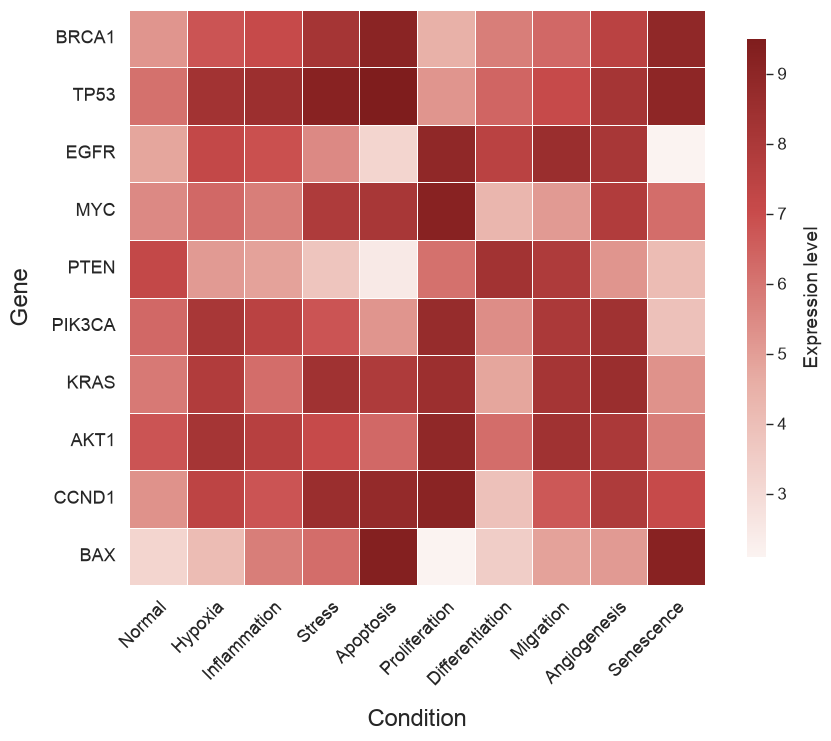

Heatmap saved to: gene_expression_heatmap.png


0

In [3]:
visualize_heatmap.main(filename, row_title, column_title, show=show, value_title=value_title)

## Notes

- Cell values are shown through the right-side color legend; numbers are not printed inside cells.
- Color scale: data that contain both negative and positive values use a blue-white-red scale centered at zero (for example z-scores in `clinical_biomarker_heatmap_demo.csv`); all other data use a light-to-dark red scale, where darker means larger.
- The output filename is generated automatically, for example `gene_expression.csv` becomes `gene_expression_heatmap.png`.
- If the CSV contains blank or non-numeric heatmap cells, the script reports the problem instead of creating a misleading image.